# E1 · Limpieza, integración y Puerta de Calidad
**Observatorio de Ocupación Hotelera de Colima** · Maximiliano Encarnación Velázquez Rodríguez

Este notebook documenta y demuestra el pipeline automático que lleva los datos de la capa **Bronce**
(crudos, inmutables) a **Plata** (limpios y validados) y **Oro** (integrados y listos para analizar).
La lógica vive en `src/pipeline/` y corre sola en GitHub Actions; aquí se ejecuta paso a paso para
mostrar la evidencia de cada decisión.

```
Bronce ─► [Puerta 1: entrada] ─► faltantes (diagnóstico + imputación) ─► [Puerta 2] ─► PLATA
PLATA  ─► integración Banxico ─► agregación ─► atípicos ─► jerarquías / discretización / normalización ─► [Puerta 3] ─► ORO
                    registros inválidos en cualquier puerta ─► data/quarantine/  (con motivo, nunca se borran)
```

In [1]:
import json, sys, warnings
from pathlib import Path
RAIZ = Path.cwd().resolve().parents[1] if Path.cwd().name == "E1" else Path.cwd()
sys.path.insert(0, str(RAIZ))
warnings.filterwarnings("ignore")

import numpy as np, pandas as pd, matplotlib.pyplot as plt
from src.pipeline import config as C, bronce, calidad, faltantes, atipicos, integracion, transformacion
from src.pipeline import ejecutar

IMG = RAIZ / "docs" / "E1" / "img"; IMG.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": .25, "font.size": 10})
pd.set_option("display.max_columns", 30); pd.set_option("display.width", 160)

ejecutar.main()   # corre el pipeline completo para que todo lo que sigue use las salidas vigentes
leer = lambda n: json.load(open(C.REPORTES / n, encoding="utf-8"))

etapa       fuente                  entrada  válidos cuarent.
1_entrada   datatur                   31147    31141        6
1_entrada   banxico_tipo_cambio        2985     2985        0
1_entrada   banxico_inpc                142      142        0
2_plata     datatur                   31288    31287        1
3_oro       oro_destino_mes            6900     6898        2

Plata: 31287 registros · Oro: 6898 destino-mes · Cuarentena: 9


## 1. Capa Bronce: datos crudos
Tres fuentes heterogéneas, tal como se capturaron (la ruta sale de la bitácora de captura):

In [2]:
dt_raw, tc_raw, inpc_raw = bronce.leer_datatur(), bronce.leer_tipo_cambio(), bronce.leer_inpc()
pd.DataFrame({
    "fuente": ["DataTur (SECTUR)", "Banxico FIX", "Banxico INPC"],
    "archivo": [bronce.archivo_vigente(f) for f in ["datatur", "banxico_tipo_cambio_fix", "banxico_inpc"]],
    "formato": ["CSV con tabuladores", "JSON", "JSON"], "frecuencia": ["mensual", "diaria", "mensual"],
    "registros": [len(dt_raw), len(tc_raw), len(inpc_raw)],
})

,fuente,archivo,formato,frecuencia,registros
0,DataTur (SECTUR),data/bronze/datatur/Base70centros_2026-11-10_m...,CSV con tabuladores,mensual,31147
1,Banxico FIX,data/bronze/banxico_tipo_cambio_fix/SF43718_ti...,JSON,diaria,2985
2,Banxico INPC,data/bronze/banxico_inpc/SP1_inpc_2026-11-14T1...,JSON,mensual,142


In [3]:
dt_raw.head(3)

,archivo_origen,fila_origen,anio,mes,tipo_centro,subtipo_centro,centro,categoria,cuartos_disponibles,cuartos_ocupados_no_residentes,cuartos_ocupados_residentes,llegada_turistas_no_residentes,llegada_turistas_residentes,turistas_noche_no_residentes,turistas_noche_residentes
0,data/bronze/datatur/Base70centros_2026-11-10_m...,2,2016,1,Centros de Playa,Integralmente Planeados,Ixtapa - Zihuatanejo,3 estrellas,10819,5333,2421,3888,2023,10116,5175.0
1,data/bronze/datatur/Base70centros_2026-11-10_m...,3,2016,1,Centros de Playa,Integralmente Planeados,Ixtapa - Zihuatanejo,4 estrellas,45090,8114,29303,3941,21399,15301,63565.0
2,data/bronze/datatur/Base70centros_2026-11-10_m...,4,2016,1,Centros de Playa,Integralmente Planeados,Ixtapa - Zihuatanejo,5 estrellas,105015,32190,47030,12240,44790,64356,109299.0


## 2. Puerta de Calidad (Pandera) y cuarentena
Cada esquema (`src/pipeline/calidad.py`) valida **tipo, dominio, rango y consistencia lógica**. La validación
es *lazy*: reúne todas las fallas, separa los registros inválidos y los envía a `data/quarantine/` con el
motivo. La suma *válidos + cuarentena = entrada* demuestra que nada se borra en silencio.

| Regla | Descripción |
|---|---|
| Dominio | `anio` 2016–año actual, `mes` 1–12, `tipo_centro`, `centro` y `categoria` dentro del catálogo |
| Rango | conteos ≥ 0; cuartos disponibles > 0; tipo de cambio 5–50; INPC 50–300 |
| R1 | cuartos ocupados ≤ cuartos disponibles |
| R2 | si hay cuartos ocupados debe haber llegadas |
| R3 | turistas-noche ≥ llegadas |
| R4 | densidad ≤ 6 turistas por cuarto ocupado |
| R5 | llave única (año, mes, centro, categoría) |
| O1 (Oro) | las razones sólo pueden ser nulas cuando las llegadas son cero |

In [4]:
cal = leer("calidad.json")
puertas = pd.DataFrame(cal["puertas"])[["etapa","fuente","registros_entrada","registros_validos","registros_cuarentena"]]
puertas["conservación"] = np.where(puertas.registros_validos + puertas.registros_cuarentena == puertas.registros_entrada, "✔", "✘")
puertas

,etapa,fuente,registros_entrada,registros_validos,registros_cuarentena,conservación
0,1_entrada,datatur,31147,31141,6,✔
1,1_entrada,banxico_tipo_cambio,2985,2985,0,✔
2,1_entrada,banxico_inpc,142,142,0,✔
3,2_plata,datatur,31288,31287,1,✔
4,3_oro,oro_destino_mes,6900,6898,2,✔


In [5]:
q = pd.concat([pd.read_csv(f) for f in sorted(C.CUARENTENA.glob("*.csv"))], ignore_index=True)
cols = [c for c in ["etapa","fuente","periodo","anio","mes","centro","categoria","motivo"] if c in q]
q[cols]

,etapa,fuente,periodo,anio,mes,centro,categoria,motivo
0,1_entrada,datatur,NaN,2020,4,San Miguel de Allende,3 estrellas,R2: hay cuartos ocupados pero cero llegadas de...
1,1_entrada,datatur,NaN,2020,5,Cancún,5 estrellas,R2: hay cuartos ocupados pero cero llegadas de...
2,1_entrada,datatur,NaN,2021,7,Ciudad Juárez,2 estrellas,R1: cuartos ocupados mayores que cuartos dispo...
3,1_entrada,datatur,NaN,2021,12,Los Mochis,1 estrella,R2: hay cuartos ocupados pero cero llegadas de...
4,1_entrada,datatur,NaN,2022,4,Los Mochis,1 estrella,R2: hay cuartos ocupados pero cero llegadas de...
5,1_entrada,datatur,NaN,2022,6,Ciudad Juárez,2 estrellas,R1: cuartos ocupados mayores que cuartos dispo...
6,2_plata,datatur,NaN,2017,5,Ciudad Juárez,2 estrellas,R2: hay cuartos ocupados pero cero llegadas de...
7,3_oro,oro_destino_mes,2020-04,2020,4,Nuevo Nayarit,NaN,estadia_promedio: estadía fuera de 1-30 noches
8,3_oro,oro_destino_mes,2020-05,2020,5,Nuevo Nayarit,NaN,estadia_promedio: estadía fuera de 1-30 noches


## 3. Valores faltantes
### 3.1 Diagnóstico
Hay dos tipos: **explícitos** (celdas vacías) e **implícitos** (combinaciones centro × categoría × mes que no
aparecen). Para los implícitos se construye la rejilla completa de 108 meses por serie.

In [6]:
f = leer("faltantes.json")
print("Explícitos:", f["faltantes_explicitos"], f["detalle_explicitos"])
print(f"Implícitos: {f['faltantes_implicitos']:,} de {f['rejilla_esperada']:,} celdas ({f['pct_implicitos']} %)")
print("Huecos por tipo:", f["huecos_por_tipo"])
pd.DataFrame({k: {"χ²": v["chi2"], "gl": v["gl"], "p-valor": f"{v['p_valor']:.1e}", "V de Cramér": v["v_cramer"]}
              for k, v in f["pruebas_independencia"].items()}).T

Explícitos: {'turistas_noche_residentes': 1} [{'anio': 2020, 'mes': 3, 'centro': 'Mexicali', 'categoria': '5 estrellas'}]
Implícitos: 2,447 de 33,588 celdas (7.29 %)
Huecos por tipo: {'estructural': 2300, 'interno_corto': 147}


,χ²,gl,p-valor,V de Cramér
anio,214.31,8,6.1e-42,0.08
categoria,6386.75,5,0.0e+00,0.436
tipo_centro,141.15,1,1.5e-32,0.065


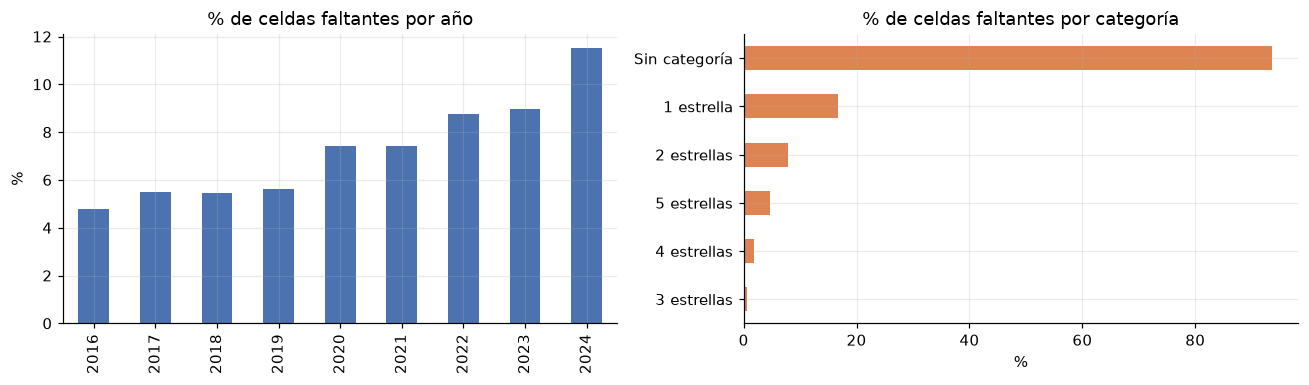

In [7]:
g = faltantes.clasificar_huecos(faltantes.rejilla(dt_raw.dropna(subset=["anio","mes"])))
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
g.groupby("anio")["falta"].mean().mul(100).plot.bar(ax=ax[0], color="#4C72B0")
ax[0].set(title="% de celdas faltantes por año", xlabel="", ylabel="%")
g.groupby("categoria")["falta"].mean().mul(100).sort_values().plot.barh(ax=ax[1], color="#DD8452")
ax[1].set(title="% de celdas faltantes por categoría", xlabel="%", ylabel="")
plt.tight_layout(); plt.savefig(IMG / "faltantes_patron.png"); plt.show()

**Mecanismo.** Si los datos fueran **MCAR**, la tasa de ausencia sería igual en todos los años, categorías y
tipos de centro. Las tres pruebas ji-cuadrada la rechazan (p ≪ 0.05): la ausencia depende sobre todo de la
**categoría** (V de Cramér = 0.44; 1★ y "Sin categoría" faltan mucho más), crece después de 2020 y es mayor en
ciudades. Por lo tanto **no es MCAR**:

* **Huecos internos cortos (≤ 3 meses)** en una serie activa: la ausencia se explica por variables observadas
  (serie, categoría, momento) → **MAR**. Se imputan dentro de su serie interpolando linealmente la oferta y las
  tasas (ocupación, llegadas por cuarto, noches por llegada) y reconstruyendo los conteos.
* **Huecos largos o en los extremos** (p. ej. Colima 5★ falta 91 meses; El Fuerte deja de reportar en 2024): la
  categoría no operaba o salió del monitoreo; la ausencia depende del valor no observado (no había oferta) →
  **MNAR / estructural**. **No se imputan**: hacerlo inventaría cuartos de hotel.
* **El único nulo explícito** (Mexicali 5★, mar-2020, turistas-noche residentes) se imputa por **razón**:
  llegadas × estadía mediana de la misma serie en ±6 meses.

Imputación explícita: [{'centro': 'Mexicali', 'categoria': '5 estrellas', 'periodo': '2020-03', 'columna': 'turistas_noche_residentes', 'metodo': 'razón mediana turistas_noche_residentes/llegada_turistas_residentes ±6 meses', 'razon': 1.1282, 'valor_imputado': 6852.0}]
Huecos internos imputados: 147


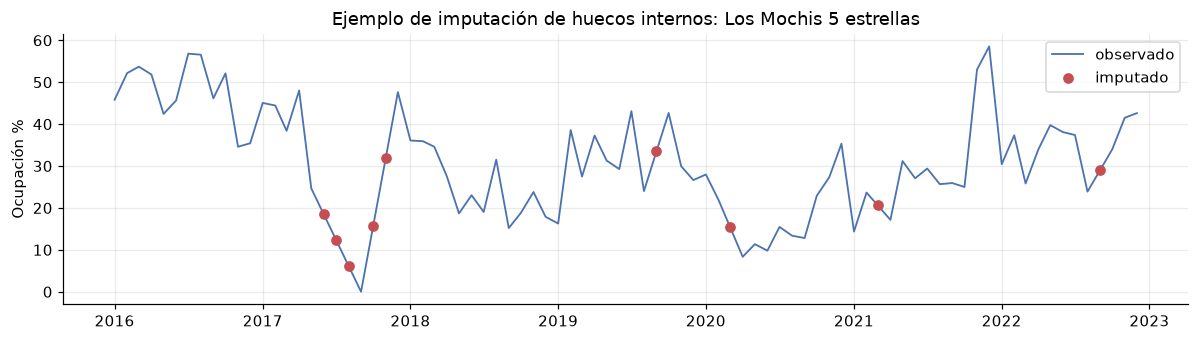

In [8]:
print("Imputación explícita:", f["imputaciones_explicitas"])
print("Huecos internos imputados:", f["huecos_imputados"])
plata = pd.read_csv(C.PLATA / "datatur_hoteles.csv")
ej = plata.groupby(["centro","categoria"])["imputado"].sum().sort_values().index[-1]
s = plata[(plata.centro == ej[0]) & (plata.categoria == ej[1])].copy()
s["fecha"] = pd.to_datetime(s.anio.astype(str) + "-" + s.mes.astype(str))
s["ocup"] = 100 * (s.cuartos_ocupados_residentes + s.cuartos_ocupados_no_residentes) / s.cuartos_disponibles
fig, ax = plt.subplots(figsize=(11, 3.2))
ax.plot(s.fecha, s.ocup, color="#4C72B0", lw=1.2, label="observado")
ax.scatter(s.fecha[s.imputado], s.ocup[s.imputado], color="#C44E52", zorder=3, label="imputado")
ax.set(title=f"Ejemplo de imputación de huecos internos: {ej[0]} {ej[1]}", ylabel="Ocupación %"); ax.legend()
plt.tight_layout(); plt.savefig(IMG / "faltantes_imputacion.png"); plt.show()

## 4. Integración de fuentes y resolución de conflictos

| Conflicto | DataTur | Banxico FIX | Banxico INPC | Resolución |
|---|---|---|---|---|
| Formato | CSV con tabuladores | JSON anidado (`bmx.series[].datos`) | JSON anidado | Ambos a DataFrame tabular |
| Llave temporal | `anio` (int) + `mes` (texto "01") | `fecha` texto dd/mm/aaaa | `fecha` día 1 del mes | Llave común `periodo` = "AAAA-MM" |
| Tipo del valor | numérico | texto ("17.3529", "N/E") | texto | `to_numeric` + Puerta de Calidad |
| Frecuencia | mensual | **diaria** (días hábiles) | mensual | FIX → promedio mensual y cierre |
| Granularidad | centro × categoría | nacional | nacional | DataTur se agrega a centro; Banxico se replica |
| Cobertura | 2016-01 – 2024-12 | 2016 – hoy | 2016 – hoy | Unión izquierda sobre DataTur (variable objetivo) |
| Unidades | cuartos-noche, personas | pesos/dólar | índice 2Q-jul-2018 = 100 | INPC → inflación anual % |

In [9]:
oro = pd.read_csv(C.ORO / "destino_mes.csv")
ir = leer("integracion_reduccion.json")
print("Periodos sin inflación:", ir["periodos_sin_inflacion"] or "ninguno")
oro[oro.centro == "Manzanillo"][["periodo","ocupacion_pct","estadia_promedio","pct_no_residentes",
                                  "tipo_cambio","dias_cotizados","inpc","inflacion_anual_pct"]].tail(6)

Periodos sin inflación: ninguno


,periodo,ocupacion_pct,estadia_promedio,pct_no_residentes,tipo_cambio,dias_cotizados,inpc,inflacion_anual_pct
3006,2024-07,61.352,2.0448,3.371,18.1117,23,136.003,5.566
3007,2024-08,53.304,1.9739,3.522,19.1515,22,136.013,4.993
3008,2024-09,45.025,1.8789,3.342,19.6316,20,136.080,4.580
3009,2024-10,49.285,1.9683,2.876,19.7062,22,136.828,4.762
3010,2024-11,55.647,1.9468,2.087,20.3455,20,137.424,4.549
3011,2024-12,59.319,2.0763,5.708,20.2661,20,137.949,4.212


> **Conflicto de cobertura resuelto:** la inflación anual necesita el INPC de 12 meses antes. En la primera versión
> la captura de Banxico arrancaba en 2016-01 y la inflación de 2016 quedaba nula. Se amplió el extractor a 2015-01 y
> la corrida automática #2 de GitHub Actions completó los valores sin intervención manual.

## 5. Atípicos y ruido
Cada serie de destino se descompone en **tendencia** (mediana móvil de 13 meses, estimada sin los meses de
choque) + **estacionalidad** (mediana por mes calendario) + **residuo**. Sobre el residuo se aplican IQR y
Z-Score robusto; atípico = marcado por **ambos** (consenso). Isolation Forest se agrega como contraste
multivariado cuando scikit-learn está disponible.

In [10]:
a = leer("atipicos.json")
pd.DataFrame({v: {k: a[v][k] for k in ["iqr","z_robusto","consenso","consenso_en_choque_conocido","winsorizados","pct_winsorizado"]}
              for v in ["ocupacion_pct","estadia_promedio"]}).T

,iqr,z_robusto,consenso,consenso_en_choque_conocido,winsorizados,pct_winsorizado
ocupacion_pct,1009.0,773.0,773.0,598.0,175.0,2.54
estadia_promedio,831.0,515.0,515.0,209.0,306.0,4.43


In [11]:
print(a['isolation_forest'])

{'disponible': True, 'atipicos': 69, 'en_choque_conocido': 21, 'contaminacion': 0.01, 'variables': ['ocupacion_pct', 'estadia_promedio', 'densidad', 'pct_no_residentes']}


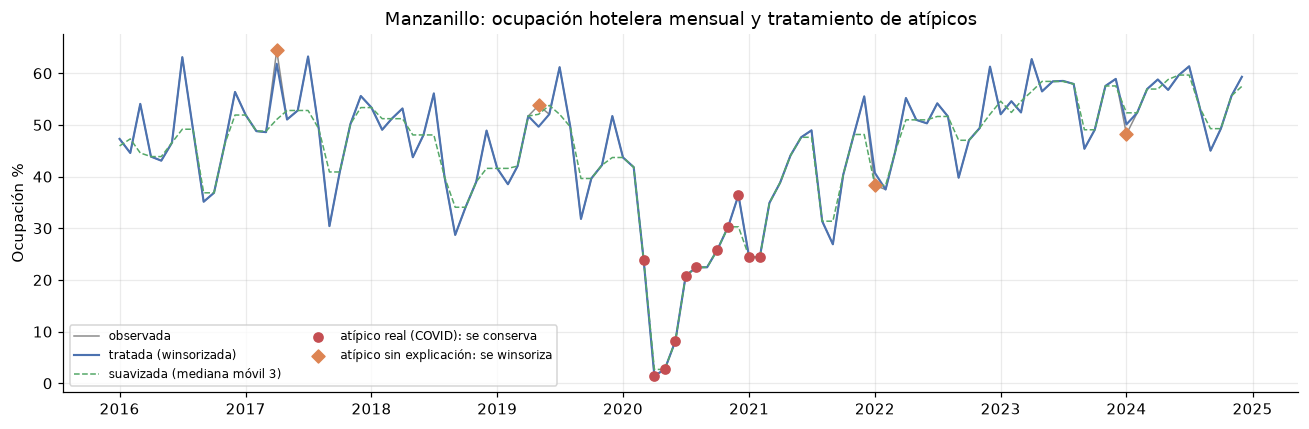

In [12]:
m = oro[oro.centro == "Manzanillo"].copy(); m["fecha"] = pd.to_datetime(m.periodo)
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(m.fecha, m.ocupacion_pct, color="#8C8C8C", lw=1, label="observada")
ax.plot(m.fecha, m.ocupacion_pct_tratada, color="#4C72B0", lw=1.4, label="tratada (winsorizada)")
ax.plot(m.fecha, m.ocupacion_pct_suavizada, color="#55A868", lw=1, ls="--", label="suavizada (mediana móvil 3)")
cov = m.atipico_ocupacion_pct & (m.evento_conocido.fillna("") != "")
win = m.atipico_ocupacion_pct & (m.evento_conocido.fillna("") == "")
ax.scatter(m.fecha[cov], m.ocupacion_pct[cov], color="#C44E52", zorder=3, label="atípico real (COVID): se conserva")
ax.scatter(m.fecha[win], m.ocupacion_pct[win], color="#DD8452", marker="D", zorder=3, label="atípico sin explicación: se winsoriza")
ax.set(title="Manzanillo: ocupación hotelera mensual y tratamiento de atípicos", ylabel="Ocupación %"); ax.legend(fontsize=8, ncol=2)
plt.tight_layout(); plt.savefig(IMG / "atipicos_manzanillo.png"); plt.show()

In [13]:
pd.DataFrame(a["ocupacion_pct"]["ejemplos_winsorizados"]).head(8)

,centro,periodo,ocupacion_pct,ocupacion_pct_tratada
0,Acapulco,2016-03,50.82,47.73
1,Aguascalientes,2019-08,51.38,53.92
2,Aguascalientes,2021-04,37.98,41.88
3,Bahías de Huatulco,2021-03,30.95,37.62
4,Bahías de Huatulco,2022-01,56.38,60.82
5,Bahías de Huatulco,2022-02,61.41,65.70
6,Campeche,2017-09,27.96,31.56
7,Cancún,2021-03,51.05,56.00


**Tratamiento.** Los atípicos en meses de **pandemia** (mar-2020 a feb-2021) o del **huracán Otis** en Acapulco
son reales: se conservan y quedan marcados (`choque_covid`, `evento_conocido`) para modelarlos como intervención
en el pronóstico. Sólo los atípicos **sin explicación** (≈ 2.5 % de los destino-mes) se winsorizan a la cerca IQR
en `ocupacion_pct_tratada`; el valor original nunca se pierde. Para el ruido se agrega una versión suavizada con
mediana móvil de 3 meses. Varios atípicos "sin explicación" caen en marzo o abril: es el efecto de **Semana Santa**,
que cambia de mes cada año. Se registra como mejora para la siguiente entrega.

## 6. Normalización y estandarización
* **Min-Max** → [0, 1]: conserva la forma de la distribución; útil para distancias (clúster, E3).
* **Z-Score** → media 0, DE 1: compara variables en distintas unidades (ocupación %, pesos por dólar, noches).
Los parámetros se guardan en `data/gold/parametros_normalizacion.json` para aplicar o revertir la transformación.

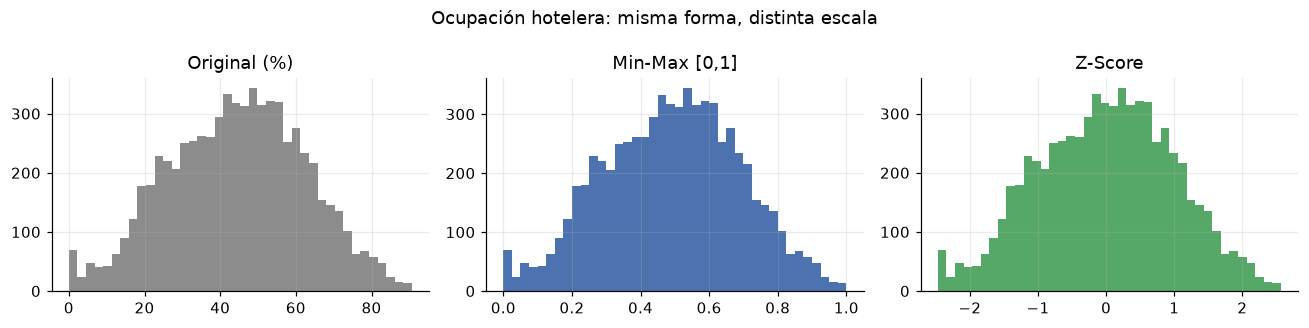

,min,max,media,desv_est
ocupacion_pct,0.000,90.661,44.472,18.006
estadia_promedio,1.000,53.412,1.810,1.281
densidad,1.007,3.961,2.008,0.454
pct_no_residentes,0.000,100.000,15.928,21.115
cuartos_disponibles,7952.000,1905162.000,197284.920,299666.036
llegadas,0.000,1230463.000,98389.405,152379.654
tipo_cambio,16.792,24.266,19.343,1.404
inflacion_anual_pct,2.148,8.700,4.961,1.632


In [14]:
fig, ax = plt.subplots(1, 3, figsize=(12, 3))
for i, (c, t) in enumerate([("ocupacion_pct", "Original (%)"), ("ocupacion_pct_minmax", "Min-Max [0,1]"), ("ocupacion_pct_z", "Z-Score")]):
    ax[i].hist(oro[c].dropna(), bins=40, color=["#8C8C8C", "#4C72B0", "#55A868"][i]); ax[i].set_title(t)
fig.suptitle("Ocupación hotelera: misma forma, distinta escala"); plt.tight_layout()
plt.savefig(IMG / "normalizacion.png"); plt.show()
pd.DataFrame(json.load(open(C.ORO / "parametros_normalizacion.json", encoding="utf-8"))).T.round(3)

## 7. Discretización y jerarquías conceptuales
| Jerarquía | Niveles (de detalle a general) |
|---|---|
| Tiempo | mes → trimestre → semestre → año · mes → temporada (Alta/Media/Baja) · año → periodo COVID |
| Espacio | centro → entidad → región Banxico (Norte, Centro Norte, Centro, Sur) → país · centro → subtipo → tipo |
| Producto | categoría (1★–5★) → segmento (Económico, Medio, Superior) |
| Comparación E3 | centro → grupo (Pacífico líder / intermedio / rezagado) · litoral (Pacífico, Golfo-Caribe) |

Discretizaciones: **ocupación** por umbrales de negocio (Baja < 40 %, Media 40–60 %, Alta ≥ 60 %) y por quintiles
(igual frecuencia); **estadía** por clases (exprés, corta, media, larga); **tipo de cambio** por terciles.

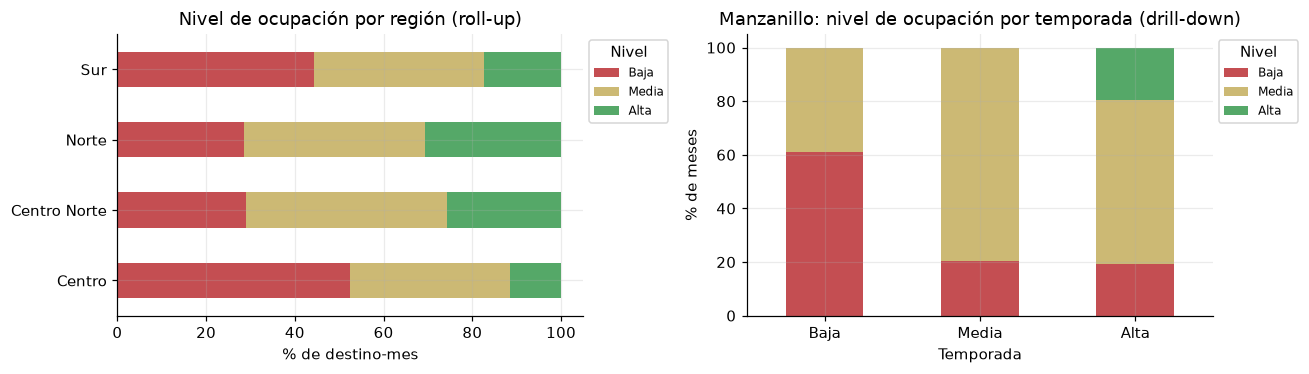

In [15]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
orden = ["Baja", "Media", "Alta"]
(pd.crosstab(oro.region, oro.ocupacion_nivel, normalize="index")[orden] * 100).plot.barh(stacked=True, ax=ax[0],
    color=["#C44E52", "#CCB974", "#55A868"])
ax[0].set(title="Nivel de ocupación por región (roll-up)", xlabel="% de destino-mes", ylabel="")
ax[0].legend(title="Nivel", bbox_to_anchor=(1.0, 1.0), loc="upper left", fontsize=8)
mz = oro[oro.centro == "Manzanillo"]
(pd.crosstab(mz.temporada, mz.ocupacion_nivel, normalize="index").reindex(columns=orden).loc[["Baja","Media","Alta"]] * 100
 ).plot.bar(stacked=True, ax=ax[1], color=["#C44E52", "#CCB974", "#55A868"], rot=0)
ax[1].set(title="Manzanillo: nivel de ocupación por temporada (drill-down)", ylabel="% de meses", xlabel="Temporada")
ax[1].legend(title="Nivel", bbox_to_anchor=(1.0, 1.0), loc="upper left", fontsize=8)
plt.tight_layout(); plt.savefig(IMG / "discretizacion_jerarquias.png"); plt.show()

In [16]:
# Roll-up en la jerarquía espacial: centro → entidad → región
(oro[oro.periodo_covid != "Pandemia"].groupby(["region","estado"])
   .apply(lambda d: 100 * d.cuartos_ocupados.sum() / d.cuartos_disponibles.sum()).rename("ocupación %").round(1)
   .sort_values(ascending=False).head(10).to_frame())

,,ocupación %
region,estado,
Centro Norte,Nayarit,75.4
Sur,Quintana Roo,75.0
Centro Norte,Baja California Sur,68.0
Norte,Nuevo León,64.7
Centro,Ciudad de México,61.7
Norte,Chihuahua,60.5
Centro,Puebla,60.0
Sur,Yucatán,59.1
Centro Norte,San Luis Potosí,58.8


## 8. Reducción de datos
1. **Agregación**: centro × categoría × mes (Plata) → centro × mes (Oro).
2. **Selección de variables** por correlación: se descarta una de cada par con |r| > 0.95.
3. **Selección de casos**: `serie_colima.csv` conserva sólo Manzanillo y Colima con las variables seleccionadas,
   lista para el pronóstico.

Agregación: 31,287 → 6,900 registros (factor 4.53×)
Pares redundantes (|r| > 0.95): ninguno
Variables seleccionadas: ['ocupacion_pct', 'estadia_promedio', 'densidad', 'pct_no_residentes', 'cuartos_disponibles', 'llegadas', 'tipo_cambio', 'inflacion_anual_pct']


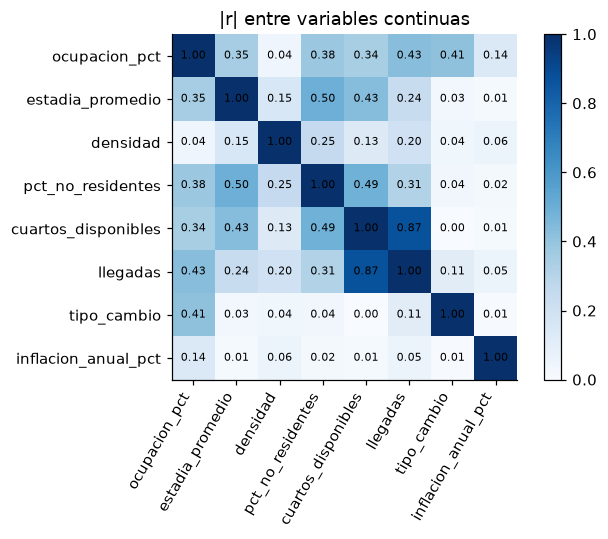

In [17]:
r = ir["reduccion_agregacion"]; s = ir["seleccion_variables"]
print(f"Agregación: {r['registros_plata']:,} → {r['registros_oro']:,} registros (factor {r['factor']}×)")
print("Pares redundantes (|r| > 0.95):", s["pares_redundantes"] or "ninguno")
print("Variables seleccionadas:", s["seleccionadas"])
corr = pd.DataFrame(s["matriz_correlacion"])
fig, ax = plt.subplots(figsize=(6.5, 5))
im = ax.imshow(corr, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns, rotation=60, ha="right"); ax.set_yticks(range(len(corr)), corr.index)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=7)
ax.set_title("|r| entre variables continuas"); ax.grid(False); plt.colorbar(im)
plt.tight_layout(); plt.savefig(IMG / "reduccion_correlacion.png"); plt.show()

Ningún par supera |r| = 0.95. La mayor correlación es entre **cuartos disponibles** y **llegadas** (≈ 0.87):
miden el tamaño del destino, no la misma cosa, así que ambas se conservan. Por eso la reducción efectiva viene de
la agregación (4.5×) y de la selección de casos.

## 9. Resultado: capas Plata y Oro

In [18]:
pd.Series(cal["salidas"]).rename("registros").to_frame()

,registros
plata_datatur,31287
oro_destino_mes,6898
oro_hotel_categoria_mes,31287
oro_serie_colima,216


In [19]:
oro[oro.centro.isin(["Manzanillo","Colima"])][["periodo","centro","ocupacion_pct","ocupacion_nivel","temporada",
   "periodo_covid","region","grupo_e3","tipo_cambio","ocupacion_pct_z","atipico_ocupacion_pct"]].tail(6)

,periodo,centro,ocupacion_pct,ocupacion_nivel,temporada,periodo_covid,region,grupo_e3,tipo_cambio,ocupacion_pct_z,atipico_ocupacion_pct
3006,2024-07,Manzanillo,61.352,Alta,Alta,Pospandemia,Centro Norte,Pacífico intermedio,18.1117,0.937437,False
3007,2024-08,Manzanillo,53.304,Media,Alta,Pospandemia,Centro Norte,Pacífico intermedio,19.1515,0.490482,False
3008,2024-09,Manzanillo,45.025,Media,Baja,Pospandemia,Centro Norte,Pacífico intermedio,19.6316,0.030698,False
3009,2024-10,Manzanillo,49.285,Media,Baja,Pospandemia,Centro Norte,Pacífico intermedio,19.7062,0.267282,False
3010,2024-11,Manzanillo,55.647,Media,Media,Pospandemia,Centro Norte,Pacífico intermedio,20.3455,0.620603,False
3011,2024-12,Manzanillo,59.319,Media,Alta,Pospandemia,Centro Norte,Pacífico intermedio,20.2661,0.824532,False


**Conclusión.** El pipeline transforma 31,147 registros crudos en una capa Oro de 6,898 destino-mes integrada
con Banxico. Las tres Puertas de Calidad dejaron 9 registros en cuarentena, cada uno con su motivo. Los faltantes
se diagnosticaron como MAR (huecos cortos, imputados) y MNAR/estructurales (no imputados). Los choques reales
(COVID, Otis) se conservaron como información y sólo se corrigieron los atípicos sin explicación. Todo corre de
forma automática en GitHub Actions después de cada captura.